# **Laboratory Task 4 — Linear Regression in PyTorch**

**Instruction:** Train a linear regression model in PyTorch using a regression dataset.

**Required parameters:**

| Parameter | Value |
|---|---|
| Criterion | MSE Loss |
| Architecture | Fully Connected Layers x 2 |
| Batch Size | 8 |
| Optimizer | SGD |
| Epochs | 1000 |

**Dataset:** [`load_diabetes`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html)
from scikit-learn — a classic regression benchmark with 442 patient records, 10 numeric features
(age, sex, BMI, blood pressure, six blood-serum measurements), and a continuous target: a quantitative
measure of disease progression one year after baseline. It's built into scikit-learn (no download
needed), which matters since this environment has no internet access.


## 1. Imports

In [1]:
#import torch test

print("PyTorch:", torch.__version__)
print(torch.rand(2, 3))

PyTorch: 2.14.0+cpu
tensor([[0.9286, 0.7185, 0.5952],
        [0.0641, 0.5789, 0.8797]])


In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)


## 2. Load and Prepare the Regression Dataset

We load the diabetes dataset, split it into training and test sets, and **standardize** both the
features (X) and the target (y). Standardization matters a lot here: SGD with a small, fixed learning
rate converges much more reliably when features are on comparable scales, without it, features with
larger raw magnitudes would dominate the gradient updates.


In [3]:
# Load dataset
data = load_diabetes()
X, y = data.data, data.target.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature names:", data.feature_names)

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardize features and target
x_scaler = StandardScaler()
X_train = x_scaler.fit_transform(X_train)
X_test = x_scaler.transform(X_test)

y_scaler = StandardScaler()
y_train = y_scaler.fit_transform(y_train)
y_test = y_scaler.transform(y_test)

print("\nTrain size:", X_train.shape[0], " Test size:", X_test.shape[0])


X shape: (442, 10)
y shape: (442, 1)
Feature names: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Train size: 353  Test size: 89


## 3. Convert to Tensors and Build the DataLoader (Batch Size = 8)

In [4]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)

print("Number of batches per epoch:", len(train_loader))


Number of batches per epoch: 45


## 4. Define the Model (2 Fully Connected Layers)

The model has exactly two `nn.Linear` layers as required:

- `fc1`: input features &rarr; hidden units
- `fc2`: hidden units &rarr; 1 output (the regression target)

A ReLU activation sits between the two layers so the second layer isn't just a linear
recombination of the first. This keeps the "2 fully connected layers" meaningful while still
producing a regression model.


In [5]:
class LinearRegressionNet(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

input_dim = X_train.shape[1]
model = LinearRegressionNet(input_dim=input_dim, hidden_dim=16)
print(model)


LinearRegressionNet(
  (fc1): Linear(in_features=10, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=1, bias=True)
)


## 5. Criterion (MSE Loss) and Optimizer (SGD)

In [6]:
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=0.01)

## 6. Training Loop (1000 Epochs)

For each epoch we iterate over all mini-batches (size 8), compute predictions, compute MSE loss,
backpropagate, and step the optimizer. We track the average loss per epoch so we can plot the
learning curve afterward.


In [7]:
num_epochs = 1000
epoch_losses = []

for epoch in range(num_epochs):
    running_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        predictions = model(batch_X)
        loss = criterion(predictions, batch_y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * batch_X.size(0)

    epoch_loss = running_loss / len(train_dataset)
    epoch_losses.append(epoch_loss)

    if (epoch + 1) % 100 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}]  Train MSE Loss: {epoch_loss:.4f}")


Epoch [100/1000]  Train MSE Loss: 0.4000
Epoch [200/1000]  Train MSE Loss: 0.3400
Epoch [300/1000]  Train MSE Loss: 0.2959
Epoch [400/1000]  Train MSE Loss: 0.2861
Epoch [500/1000]  Train MSE Loss: 0.2707
Epoch [600/1000]  Train MSE Loss: 0.2560
Epoch [700/1000]  Train MSE Loss: 0.2408
Epoch [800/1000]  Train MSE Loss: 0.2278
Epoch [900/1000]  Train MSE Loss: 0.2263
Epoch [1000/1000]  Train MSE Loss: 0.2728


The training loss generally decreased throughout the 1,000 epochs, falling from 0.4000 at epoch 100 to a minimum of approximately 0.2263 at epoch 900. This indicates that the model was learning from the training data and improving its predictions over time. The increase to 0.2728 at epoch 1,000 shows some fluctuation in the training process, which can occur with stochastic gradient descent (SGD), particularly when updates are based on small batches. The decreasing trend suggests that the chosen learning rate and number of epochs allowed the model to learn effectively, although the final increase indicates that the loss did not decrease monotonically.


## 7. Plot the Training Loss Curve

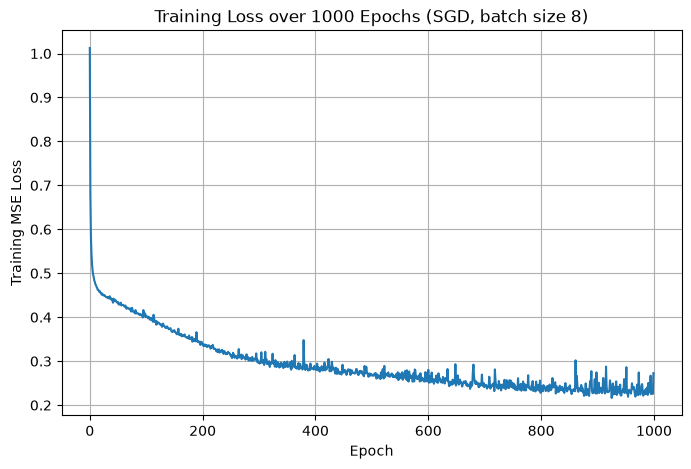

In [8]:
plt.figure(figsize=(8, 5))
plt.plot(epoch_losses)
plt.xlabel("Epoch")
plt.ylabel("Training MSE Loss")
plt.title("Training Loss over 1000 Epochs (SGD, batch size 8)")
plt.grid(True)
plt.show()


## 8. Evaluate on the Test Set

In [9]:
model.eval()
with torch.no_grad():
    test_predictions = model(X_test_t)
    test_loss = criterion(test_predictions, y_test_t)

print("Final Test MSE Loss (standardized scale):", test_loss.item())

# Convert predictions back to the original target scale for interpretability
test_predictions_original = y_scaler.inverse_transform(test_predictions.numpy())
y_test_original = y_scaler.inverse_transform(y_test_t.numpy())

mae_original = np.mean(np.abs(test_predictions_original - y_test_original))
print("Mean Absolute Error (original target scale):", mae_original)


Final Test MSE Loss (standardized scale): 0.5948104858398438
Mean Absolute Error (original target scale): 45.50202


## 9. Predicted vs. Actual Plot

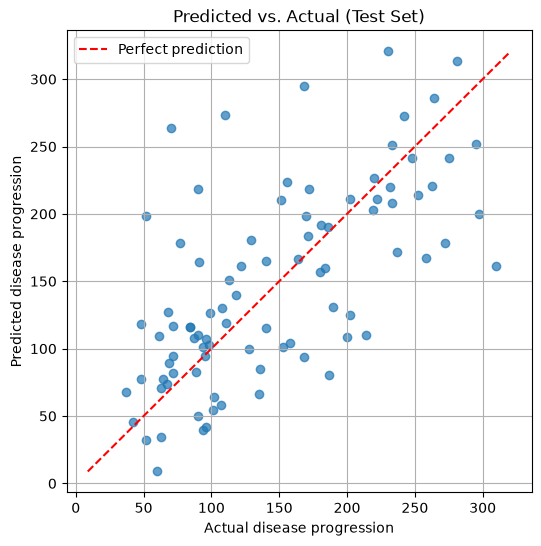

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test_original, test_predictions_original, alpha=0.7)
min_val = min(y_test_original.min(), test_predictions_original.min())
max_val = max(y_test_original.max(), test_predictions_original.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', label="Perfect prediction")
plt.xlabel("Actual disease progression")
plt.ylabel("Predicted disease progression")
plt.title("Predicted vs. Actual (Test Set)")
plt.legend()
plt.grid(True)
plt.show()


## 10. Analysis & Discussion

### 10.1 Training Loss Analysis

The training loss generally decreased throughout the 1,000 training epochs, indicating that the neural network was learning to minimize its prediction error. During the early stages of training, the loss decreased rapidly, dropping from above 1.0 to approximately 0.46 within the first several epochs. After this initial decrease, the loss continued to decline more gradually, reaching approximately 0.23–0.27 toward the end of training. This pattern indicates rapid initial learning followed by gradual refinement of the model's parameters.

The loss curve also exhibits noticeable fluctuations throughout training rather than a perfectly smooth decline. This behavior is expected when using **stochastic gradient descent (SGD) with a batch size of 8**, because each parameter update is based on a relatively small subset of the training data. Consequently, individual batches can produce different gradient estimates, causing the loss to fluctuate between epochs.

A notable increase occurs between epochs 900 and 1,000, where the reported training MSE increases from **0.2263 to 0.2728**. This does not necessarily indicate that the model has diverged. Instead, it is consistent with the fluctuations observed in the later portion of the training curve, where the loss remains within an approximate range rather than continuing to decrease smoothly. Since a fixed learning rate was used, the SGD updates may continue to move the model around a region near a minimum instead of settling at one exact point. Therefore, the overall decreasing trend is more informative than the increase observed in the final logged epoch.

Overall, the training curve demonstrates that the model successfully learned from the training data, although convergence was accompanied by the expected variability associated with mini-batc#h SGD.

### 10.2 Test Set Performance

The model achieved a **test MSE of approximately 0.595 on the standardized target**, compared with a final training MSE of approximately **0.23–0.27**. The higher error on the test set indicates that the model performs better on the training data than on unseen data. This train–test gap suggests that some degree of **overfitting or high variance** may be present.

The relatively small size of the dataset may contribute to this behavior. The diabetes dataset contains only **442 observations**, with approximately 353 observations used for training. With a neural network architecture of 10 input features, a hidden layer of 16 neurons, and one output neuron, the model has enough parameters to learn patterns specific to the training data. With a relatively small dataset, some of these learned patterns may not generalize as well to unseen observations.

On the original disease-progression scale, the model obtained an **MAE of approximately 45.5**. Considering that the target values range from roughly 25 to 346, this represents a substantial average prediction error. Thus, while the model captures some of the underlying relationship between the input variables and disease progression, its predictions are not highly precise.

The model's approximate **R² of 0.40** further indicates that it explains a meaningful portion of the variation in the target variable while leaving a considerable amount unexplained. This is not unexpected for the diabetes dataset, where the target represents a biological outcome influenced by multiple factors and therefore contains inher#ent variability.

### 10.3 Predicted vs. Actual Values

The predicted-versus-actual scatter plot provides a visual assessment of how closely the model's predictions correspond to the observed target values. Ideally, predictions should fall close to the diagonal line representing perfect agreement between predicted and actual values.

In the plot, the predictions show a reasonable alignment with the diagonal in the low-to-middle range of the target values. However, the points become more widely scattered at higher target values, particularly around **250 and above**. This indicates that the model has greater difficulty accurately predicting observations at the upper end of the target distribution.

The increased spread of prediction errors at higher values may be related to the distribution of the dataset and the limited number of observations at the extremes. With fewer examples representing these higher disease-progression values, the model has less training information from which to learn the corresponding patterns. Consequently, predictions for extreme observations may be less reliable than predictions for values within the denser middle# portion of the dataset.

### 10.4 Discussion

The results indicate that the neural network successfully learned meaningful patterns from the training data, as demonstrated by the substantial decrease in training loss. However, the higher test error and the difference between training and test performance indicate that the learned patterns do not generalize perfectly to unseen data.

Several factors may explain this result. First, the **small dataset size** limits the amount of information available for training a neural network. Second, the use of **batch size 8 and a fixed learning rate** contributes to the fluctuations observed in the training loss. Although these settings allow the model to learn, they can prevent the loss from settling smoothly around its minimum.

The results also suggest that increasing the number of epochs alone may not necessarily improve generalization. Once the model reaches a region where the training loss fluctuates around a minimum, additional training can continue adapting the model to the training data without producing corresperalization when assessing a machine learning model.
